# Bonus Track 5.- Correlación de datos

* El coeficiente de correlación de Pearson mide la **relación lineal** entre dos variables numéricas y toma valores entre −1 y 1.
* Valores próximos a 1 o −1 indican una relación lineal fuerte, positiva o negativa; un valor próximo a 0 indica poca relación lineal, aunque puede existir una relación no lineal. Correlación no implica causalidad.
* Variables de entrada muy correlacionadas pueden aportar información redundante. Eliminarlas puede simplificar el modelo, pero no siempre mejora sus resultados: depende del problema y del algoritmo.
* La selección debe ajustarse con los datos de entrenamiento y aplicarse después a test y a datos nuevos, sin incluir la variable objetivo en la selección.

<hr>

## 1. Cargamos los datos

* Utilizamos el dataset de calorías y añadimos `Peso_gramos`, una copia de `Peso` expresada en gramos, para ilustrar la redundancia. Reservamos datos de test antes de calcular la correlación.


In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

df = pd.read_csv("./datasets/calories_time_weight_speed.csv")
df['Peso_gramos'] = df['Peso'] * 1000
objetivo = 'Calorias'
X = df.drop(columns=[objetivo])
y = df[objetivo]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
X_train.sample(5, random_state=42)


,Tiempo,Peso,Velocidad,Peso_gramos
682,39.2,68.6,12.1,68600.0
4312,5.9,66.3,13.1,66300.0
647,66.1,70.5,11.1,70500.0
878,35.0,68.4,10.2,68400.0
777,68.8,72.7,11.1,72700.0


<hr>


## 2. Correlación entre variables

* Con la funcion de pandas ***.corr()***, nos devuelve la matriz de correlaciones entre cada par de variables de entrada del conjunto de entrenamiento:

In [2]:
df_corr = X_train.corr()
df_corr


,Tiempo,Peso,Velocidad,Peso_gramos
Tiempo,1.000000,-0.009497,-0.298560,-0.009497
Peso,-0.009497,1.000000,-0.014181,1.000000
Velocidad,-0.298560,-0.014181,1.000000,-0.014181
Peso_gramos,-0.009497,1.000000,-0.014181,1.000000


* Los valores cercanos a 1 y -1 nos indican que son variables muy correladas entre sí y cuanto más cercano sea el valor a 0 nos indican poca correlación lineal; pueden tener relaciones no lineales.


* Como nos interesa saber el grado de correlación, podemos pasar esos valores a su valor absoluto.


* De la matriz de correlaciones solo nos interesa la matriz triangular superior o la inferior que es donde tenemos las correlaciones entre cada para de variables.


* Para ello vamos a quedarnos con el valor absoluto de la matriz triangular superior para ver las relaciones entre cada par de variables:

In [3]:
df_corr = X_train.corr().abs()
df_upper = df_corr.where(np.triu(np.ones(df_corr.shape), k=1).astype(np.bool_))
df_upper

,Tiempo,Peso,Velocidad,Peso_gramos
Tiempo,NaN,0.009497,0.298560,0.009497
Peso,NaN,NaN,0.014181,1.000000
Velocidad,NaN,NaN,NaN,0.014181
Peso_gramos,NaN,NaN,NaN,NaN


<hr>


## 3. Mapa de calor: Correlación entre variables


* El mapa de calor nos va a permitir ver de manera más sencilla la correlación entre variables:

<Axes: >

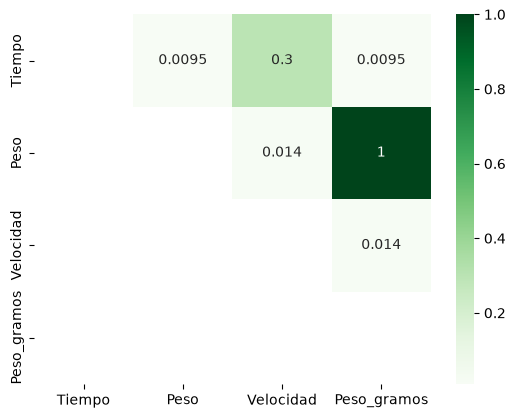

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline 

sns.heatmap(df_upper, annot=True, cmap="Greens")

<hr>

## 4. Eliminación de variables altamente correladas

* Como ejemplo, identificamos pares de variables de entrada con correlación absoluta superior a 0,95 y conservamos la primera según el orden de las columnas. El umbral y la variable que se conserva deben valorarse para cada problema.
* La selección se calcula solo con entrenamiento y se aplica también a test. La variable objetivo no interviene en esta selección.


In [5]:
umbral = 0.95
to_drop = [columna for columna in df_upper.columns if (df_upper[columna] > umbral).any()]
print("Columnas a eliminar:", to_drop)
X_train_seleccionado = X_train.drop(columns=to_drop)
X_test_seleccionado = X_test.drop(columns=to_drop)
X_train_seleccionado.sample(5, random_state=42)


Columnas a eliminar: ['Peso_gramos']


,Tiempo,Peso,Velocidad
682,39.2,68.6,12.1
4312,5.9,66.3,13.1
647,66.1,70.5,11.1
878,35.0,68.4,10.2
777,68.8,72.7,11.1
